# Random Baselines — The Floor

**Purpose**: establish a lower bound on what *any* trained model must beat. If a model can't beat random, it hasn't learned anything beyond the marginal label distribution. This is **not** the bar for "is my model worth the complexity" (that's logistic regression) — this is the bar for "did learning happen at all."

**Three flavors of random**, evaluated on the same test set as every other model:

| Baseline | What it does | Theoretical macro F1 |
|---|---|---|
| **All-zeros** | Predict no class is present, for every segment | 0.0 |
| **Stratified (per-class prior)** | For each class `c`, predict positive at probability `p_c` (the class's train rate) | `mean(p_c)` ≈ 0.05 |
| **Uniform random** | Predict positive at 50% for every (segment, class) | `mean(p_c / (p_c + 0.5))` ≈ 0.10 |

**The "right" floor is `stratified`** — it has access to the *marginal* label distribution (which is free information) but no actual learning signal. Beating it means the features carry information beyond per-class frequency. The other two are included for transparency.

**This baseline applies to both Strategy A and Strategy B** — the test set is identical between them and the random predictions don't depend on training data. We save the result under Strategy A's results folder; for comparison purposes it's the floor for both.

In [1]:
# ============================================================================
# CELL 1 — Setup
# ============================================================================
import sys
from pathlib import Path

_SHARED = Path.cwd().resolve().parents[1] / '_shared'
if str(_SHARED) not in sys.path:
    sys.path.insert(0, str(_SHARED))

import json
from datetime import datetime
import numpy as np
import matplotlib.pyplot as plt

from data import load_splits, find_root, load_config
from eval import classification_report
from plot import plot_per_class_f1

# --- Config --------------------------------------------------------------
STRATEGY    = 'A'         # see header: A's results folder doubles as the floor for both
MODEL_NAME  = 'random'
NOTEBOOK_ID = '02b'
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# --- Paths ---------------------------------------------------------------
ROOT      = find_root()
CONFIG    = load_config()
ARTIFACTS = ROOT / CONFIG['paths'][f'strategy_{STRATEGY.lower()}_artifacts']
RESULTS_DIR = ARTIFACTS / 'results'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Strategy:    {STRATEGY}")
print(f"Model:       {MODEL_NAME}")
print(f"Results dir: {RESULTS_DIR}")

Strategy:    A
Model:       random
Results dir: /Users/amrabdullah/AI_2026ss/mlpc/strategy_A_baseline/artifacts/results


## Cell 2 — Load data and compute per-class priors from train

Priors come from **train only** — we never peek at val/test, even for a random baseline. This is the principled answer; in practice for stratified random it makes ~zero numerical difference, but the discipline matters.

In [2]:
# ============================================================================
# CELL 2 — Load splits, compute per-class priors
# ============================================================================
d = load_splits(STRATEGY)
print(d.summary())

priors = d.Y_train.mean(axis=0)              # (C,)  per-class positive rate
class_names = list(d.class_names)

print(f"\nPer-class prior (train):")
for c, cls in enumerate(class_names):
    print(f"  {cls:<30s}  {priors[c]*100:>6.3f}%  "
          f"({int(d.Y_train[:, c].sum()):>6,d} positives)")

mean_prior = float(priors.mean())
print(f"\nMean prior (≈ theoretical macro F1 for stratified random): {mean_prior:.4f}")

Strategy A
  X_train: (100166, 960)  Y_train: (100166, 15)
  X_val:   (34245, 960)  Y_val:   (34245, 15)
  X_test:  (33828, 960)  Y_test:  (33828, 15)
  D = 960 features, C = 15 classes

Per-class prior (train):
  bell_ringing                     1.089%  ( 1,091 positives)
  coffee_machine                   3.782%  ( 3,788 positives)
  cutlery_dishes                   6.029%  ( 6,039 positives)
  door_open_close                  3.572%  ( 3,578 positives)
  footsteps                       11.414%  (11,433 positives)
  keyboard_typing                  9.108%  ( 9,123 positives)
  keychain                         4.562%  ( 4,570 positives)
  light_switch                     0.273%  (   273 positives)
  microwave                        6.812%  ( 6,823 positives)
  phone_ringing                    6.263%  ( 6,273 positives)
  running_water                   12.825%  (12,846 positives)
  toilet_flushing                  3.165%  ( 3,170 positives)
  vacuum_cleaner                   6.391%  (

## Cell 3 — Generate the three baselines on test, evaluate

For multi-label random predictions:
- `Y_pred[n, c] ~ Bernoulli(q_c)` independently of `Y_true`.
- `precision[c] = P(Y_true=1 | Y_pred=1) = p_c` (independence — doesn't depend on `q_c`!)
- `recall[c]    = P(Y_pred=1 | Y_true=1) = q_c`
- `F1[c]        = 2*p_c*q_c / (p_c + q_c)`

So:
- **Stratified** (`q = p`): F1 ≈ `p_c` per class → macro F1 ≈ `mean(p)`.
- **Uniform** (`q = 0.5`): F1 ≈ `p_c / (p_c + 0.5)` per class.

We compute both empirically and compare to theory below.

In [3]:
# ============================================================================
# CELL 3 — Generate three baselines + evaluate on test
# ============================================================================
np.random.seed(RANDOM_SEED)

# Baseline 1: all-zeros (predict nothing)
Y_test_zeros = np.zeros_like(d.Y_test, dtype=np.int8)

# Baseline 2: stratified by per-class prior (the principled floor)
Y_test_strat = (np.random.rand(*d.Y_test.shape) < priors[None, :]).astype(np.int8)

# Baseline 3: uniform random (q = 0.5 for every cell)
Y_test_unif = (np.random.rand(*d.Y_test.shape) < 0.5).astype(np.int8)

# Evaluate all three
report_zeros = classification_report(d.Y_test, Y_test_zeros, class_names)
report_strat = classification_report(d.Y_test, Y_test_strat, class_names)
report_unif  = classification_report(d.Y_test, Y_test_unif,  class_names)

# Theoretical expectations for comparison
theoretical_strat_macro = float(priors.mean())
theoretical_unif_macro  = float((priors / (priors + 0.5)).mean())

print(f"=== Three random baselines on test ===\n")
print(f"  {'baseline':<35s}  {'macro_f1':>9s}  {'micro_f1':>9s}  {'theory':>9s}")
print(f"  " + "-" * 67)
print(f"  {'all-zeros':<35s}  "
      f"{report_zeros.loc['macro avg', 'f1']:>9.4f}  "
      f"{report_zeros.loc['micro avg', 'f1']:>9.4f}  "
      f"{0.0:>9.4f}")
print(f"  {'stratified (per-class prior)':<35s}  "
      f"{report_strat.loc['macro avg', 'f1']:>9.4f}  "
      f"{report_strat.loc['micro avg', 'f1']:>9.4f}  "
      f"{theoretical_strat_macro:>9.4f}")
print(f"  {'uniform random (q=0.5)':<35s}  "
      f"{report_unif.loc['macro avg', 'f1']:>9.4f}  "
      f"{report_unif.loc['micro avg', 'f1']:>9.4f}  "
      f"{theoretical_unif_macro:>9.4f}")

print(f"\n→ Stratified is the principled floor. Your trained models must beat "
      f"≈ {report_strat.loc['macro avg', 'f1']:.3f} macro F1 to demonstrate learning.")

=== Three random baselines on test ===

  baseline                              macro_f1   micro_f1     theory
  -------------------------------------------------------------------
  all-zeros                               0.0000     0.0000     0.0000
  stratified (per-class prior)            0.0531     0.0785     0.0524
  uniform random (q=0.5)                  0.0910     0.0950     0.0911

→ Stratified is the principled floor. Your trained models must beat ≈ 0.053 macro F1 to demonstrate learning.


## Cell 4 — Per-class breakdown for the stratified baseline

The headline number can hide variation across classes. For stratified random the expected per-class F1 *is* the per-class prior — common classes get higher random F1, rare classes get near-zero. This is exactly the imbalance trained models are also fighting against.

In [4]:
# ============================================================================
# CELL 4 — Per-class table (stratified baseline)
# ============================================================================
print(f"=== STRATIFIED baseline — per-class F1 (sorted by support) ===\n")
print(report_strat.drop(index=['macro avg', 'micro avg', 'weighted avg'])
      .sort_values('support', ascending=True)
      .round(4)
      .to_string())

print(f"\n=== Aggregate rows ===")
print(report_strat.loc[['macro avg', 'micro avg', 'weighted avg']].round(4).to_string())

=== STRATIFIED baseline — per-class F1 (sorted by support) ===

                            precision  recall      f1  support
class                                                         
light_switch                   0.0000  0.0000  0.0000     88.0
window_open_close              0.0069  0.0076  0.0073    393.0
bell_ringing                   0.0188  0.0145  0.0164    483.0
wardrobe_drawer_open_close     0.0166  0.0193  0.0178    569.0
toilet_flushing                0.0337  0.0325  0.0331   1076.0
door_open_close                0.0391  0.0446  0.0416   1077.0
coffee_machine                 0.0402  0.0413  0.0407   1236.0
keychain                       0.0416  0.0441  0.0428   1474.0
vacuum_cleaner                 0.0540  0.0617  0.0576   1992.0
cutlery_dishes                 0.0733  0.0729  0.0731   2045.0
phone_ringing                  0.0611  0.0626  0.0618   2076.0
microwave                      0.0736  0.0640  0.0685   2579.0
keyboard_typing                0.0948  0.0888  0.0917 

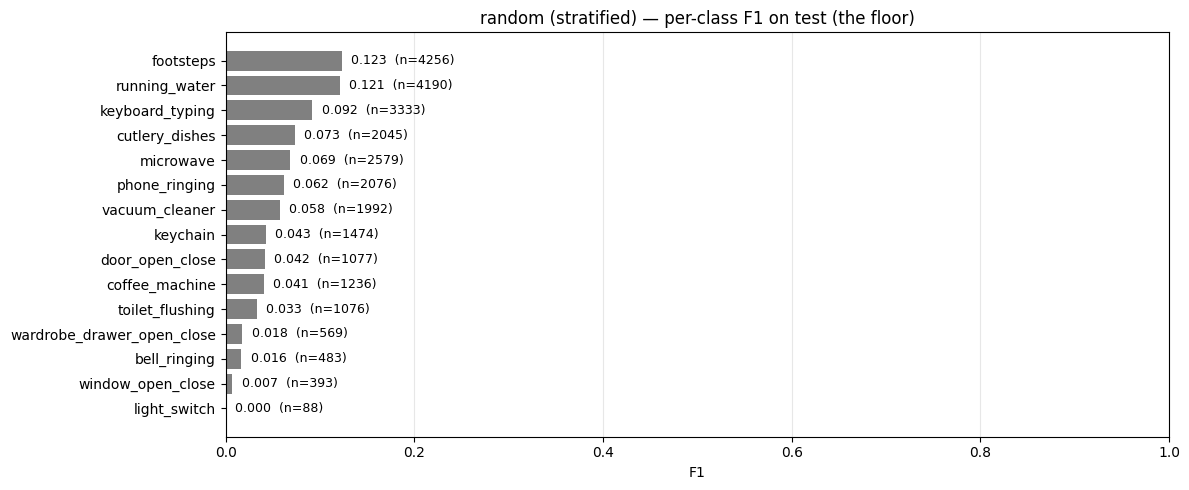

In [5]:
# ============================================================================
# CELL 5 — Plot per-class F1 for the stratified baseline
# ============================================================================
fig, ax = plot_per_class_f1(
    report_strat, class_names=class_names,
    title=f"{MODEL_NAME} (stratified) — per-class F1 on test (the floor)",
    color='gray',
)
fig.savefig(RESULTS_DIR / f"{NOTEBOOK_ID}_{MODEL_NAME}_per_class_f1.png",
            dpi=150, bbox_inches='tight')
plt.show()

## Cell 6 — Save results JSON

Saved with the same schema as `03_logreg.json` so the downstream comparison notebook can load both identically. The "winning config" for the random baseline is **stratified** — that's the principled floor.

In [6]:
# ============================================================================
# CELL 6 — Save results
# ============================================================================
def df_to_jsonable(df):
    return {idx: {col: (int(v) if col == 'support' else float(v))
                  for col, v in row.items()}
            for idx, row in df.iterrows()}

results = {
    'meta': {
        'strategy':       STRATEGY,
        'model':          MODEL_NAME,
        'notebook_id':    NOTEBOOK_ID,
        'timestamp':      datetime.now().isoformat(timespec='seconds'),
        'random_seed':    RANDOM_SEED,
        'n_train':        int(d.N_train),
        'n_val':          int(d.N_val),
        'n_test':         int(d.N_test),
        'note':           'Random baseline. Test set is identical between Strategy A '
                          'and B, so this floor applies to both.',
    },
    'winning_config': {
        'config_id':      2,
        'description':    'stratified random (per-class Bernoulli with q=p_c)',
        'hyperparameters': {'random_seed': RANDOM_SEED},
    },
    'all_baselines': {
        'all_zeros': {
            'description':  'predict no class is positive, ever',
            'macro_f1':     float(report_zeros.loc['macro avg', 'f1']),
            'micro_f1':     float(report_zeros.loc['micro avg', 'f1']),
            'weighted_f1':  float(report_zeros.loc['weighted avg', 'f1']),
        },
        'stratified': {
            'description':  'per-class Bernoulli with rate = train prior',
            'theoretical_macro_f1': theoretical_strat_macro,
            'macro_f1':     float(report_strat.loc['macro avg', 'f1']),
            'micro_f1':     float(report_strat.loc['micro avg', 'f1']),
            'weighted_f1':  float(report_strat.loc['weighted avg', 'f1']),
        },
        'uniform': {
            'description':  'Bernoulli with q=0.5 for every class',
            'theoretical_macro_f1': theoretical_unif_macro,
            'macro_f1':     float(report_unif.loc['macro avg', 'f1']),
            'micro_f1':     float(report_unif.loc['micro avg', 'f1']),
            'weighted_f1':  float(report_unif.loc['weighted avg', 'f1']),
        },
    },
    'test_report':  df_to_jsonable(report_strat),
    'headline_test': {
        'macro_f1':    float(report_strat.loc['macro avg', 'f1']),
        'micro_f1':    float(report_strat.loc['micro avg', 'f1']),
        'weighted_f1': float(report_strat.loc['weighted avg', 'f1']),
    },
}

out_path = RESULTS_DIR / f"{NOTEBOOK_ID}_{MODEL_NAME}.json"
with open(out_path, 'w') as f:
    json.dump(results, f, indent=2)

print(f"Saved: {out_path}")
print(f"\n=== HEADLINE (the floor) ===")
print(f"  Random (stratified) macro F1: {results['headline_test']['macro_f1']:.4f}")
print(f"  Random (stratified) micro F1: {results['headline_test']['micro_f1']:.4f}")
print(f"\nFor reference (Strategy A):")
print(f"  LogReg Config 3       macro F1: 0.4723   (≈ 10x better than random)")
print(f"\nFor any future model: macro F1 < {results['headline_test']['macro_f1']:.3f} → no learning happened.")

Saved: /Users/amrabdullah/AI_2026ss/mlpc/strategy_A_baseline/artifacts/results/02b_random.json

=== HEADLINE (the floor) ===
  Random (stratified) macro F1: 0.0531
  Random (stratified) micro F1: 0.0785

For reference (Strategy A):
  LogReg Config 3       macro F1: 0.4723   (≈ 10x better than random)

For any future model: macro F1 < 0.053 → no learning happened.
